# 12 · Time Series Forecasting

Forecasting is predicting the future of a quantity measured over time: electricity demand, sales, river
flow, traffic. There is no single best method. This notebook runs seven techniques, from a one-line
baseline to a Transformer, on **two problems chosen to have opposite winners**, and explains why each wins
where it does.

Running every model takes about 25 minutes on a laptop CPU (the neural networks take most of it); the
saved results below can be read without running anything.

**You will learn**
1. The families of forecasting methods and how to evaluate them without fooling yourself
2. Seasonal naive, SARIMA, Prophet, gradient boosting (XGBoost), a GRU in PyTorch, an LSTM in Keras and a Transformer, implemented on the same problem
3. **Example 1, bike-sharing demand**: tabular data with strong known features, where gradient boosting wins
4. **Example 2, river flow driven by rain**: hidden state and long, smooth responses, where recurrent neural networks win
5. A decision guide for real projects

## 1. The landscape

| Family | Examples | Learns from | Strong when |
|---|---|---|---|
| Naive baselines | last value, **seasonal naive** | nothing | always the first thing to beat |
| Classical statistical | ARIMA, **SARIMA**, ETS | one series' own past | short, stable, single series; uncertainty intervals |
| Decomposable | **Prophet** | trend + seasonalities + holidays + regressors | business series with clear calendar effects, analysts who need interpretable components |
| Machine learning on features | **XGBoost**, LightGBM, random forests | a table of engineered features (lags, calendar, covariates) | tabular problems with informative features and moderate data, most competition wins |
| Recurrent networks | **GRU**, **LSTM** | raw sequences | long memory, hidden state, many related series |
| Attention | **Transformers** (TFT, PatchTST, Informer) | raw sequences, all positions at once (often grouped into patches) | long contexts, lots of data |
| Foundation models | Chronos, TimesFM, Moirai | pretrained on millions of series | zero-shot forecasts without training |

**Evaluating forecasts honestly**
- Split by **time**, never randomly: train on the past, test on the future.
- Use **rolling origins**: forecast from many points in the test period, as the model would be used.
- Every feature must be **known at forecast time**: yesterday's demand yes, tomorrow's actual demand no.
  Weather for the next day comes from a weather forecast; here we use the observed weather as a stand-in,
  which is common practice and slightly optimistic for every model alike.
- Always report a **baseline**: a fancy model that cannot beat seasonal naive is not useful.

## 2. Example 1: hourly bike-sharing demand
Two years (2011-2012) of hourly rentals from Washington D.C.'s Capital Bikeshare with the weather and the
calendar: the UCI *Bike Sharing* dataset (Fanaee-T and Gama, 2013, licence CC BY 4.0), from OpenML. The
copy on OpenML drops the date column; the rows are in time order, so the timestamps are rebuilt from the
year, month, weekday and hour fields, and 165 missing hours (no rentals recorded) are filled.

**Task:** every midnight, forecast the 24 hourly counts of the coming day. Train on January 2011 to September
2012, test on the 92 days of October to December 2012.

In [1]:
import os, time, warnings, logging
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

raw = fetch_openml(data_id=42712, as_frame=True, parser="auto").frame
# a new day starts whenever the hour goes back down or the weekday changes
day, days, prev_h, prev_wd = 0, [], None, None
for h, wd in zip(raw["hour"].astype(int), raw["weekday"].astype(str)):
    if prev_h is not None and (h <= prev_h or wd != prev_wd):
        day += 1
    days.append(day); prev_h, prev_wd = h, wd
raw.index = pd.Timestamp("2011-01-01") + pd.to_timedelta(days, "D") + pd.to_timedelta(raw["hour"].astype(int), "h")
assert (raw.index.dayofweek == (raw["weekday"].astype(int) + 6) % 7).all()     # rebuilt dates match the weekdays

WEATHER = ["temp", "feel_temp", "humidity", "windspeed"]
bike = raw.reindex(pd.date_range(raw.index.min(), raw.index.max(), freq="h"))
bike["count"] = bike["count"].fillna(0)
for c in WEATHER + ["weather", "holiday", "workingday"]:
    bike[c] = bike[c].ffill()
bike = pd.DataFrame({
    "count": bike["count"].astype(float),
    **{c: bike[c].astype(float) for c in WEATHER},
    "weather": bike["weather"].astype(str).astype("category").cat.codes,
    "holiday": bike["holiday"].astype(str).isin(["True", "1"]).astype(int),
    "workingday": bike["workingday"].astype(str).isin(["True", "1"]).astype(int),
}, index=bike.index)
bike["hour"], bike["dow"], bike["month"] = bike.index.hour, bike.index.dayofweek, bike.index.month
print(bike.shape, bike.index.min(), "->", bike.index.max())
bike.head(3)

(17544, 11) 2011-01-01 00:00:00 -> 2012-12-31 23:00:00


,count,temp,feel_temp,humidity,windspeed,weather,holiday,workingday,hour,dow,month
2011-01-01 00:00:00,16.0,9.84,14.395,0.81,0.0,0,0,0,0,5,1
2011-01-01 01:00:00,40.0,9.02,13.635,0.80,0.0,0,0,0,1,5,1
2011-01-01 02:00:00,32.0,9.02,13.635,0.80,0.0,0,0,0,2,5,1


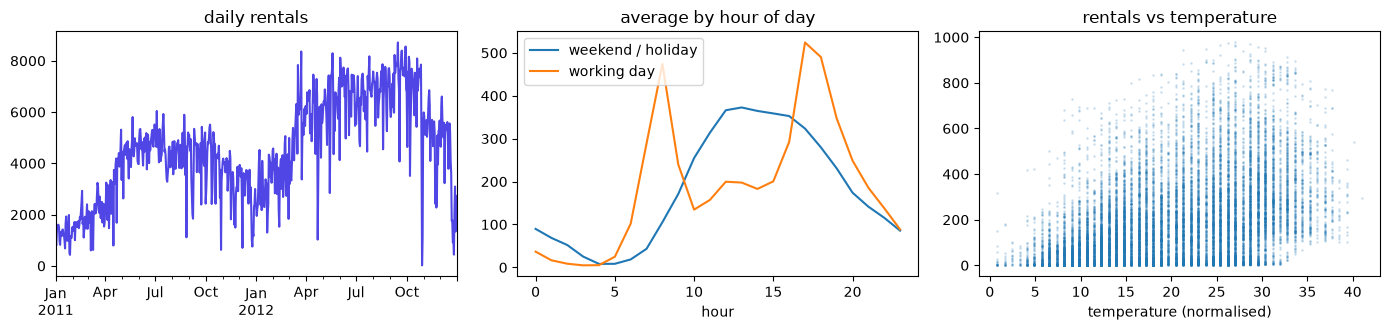

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
bike["count"].resample("D").sum().plot(ax=ax[0], title="daily rentals", color="#4f46e5")
for wd, g in bike.groupby("workingday"):
    g.groupby("hour")["count"].mean().plot(ax=ax[1], label="working day" if wd else "weekend / holiday")
ax[1].legend(); ax[1].set_title("average by hour of day")
ax[2].scatter(bike["temp"], bike["count"], s=1, alpha=.15); ax[2].set_xlabel("temperature (normalised)"); ax[2].set_title("rentals vs temperature")
plt.tight_layout(); plt.show()

The data has everything that makes forecasting with features easy: two strong daily patterns (commuting
peaks on working days, a midday hump at weekends), growth from 2011 to 2012, and a strong dependence on
weather. We model `log(1 + count)` so errors at night and at rush hour count proportionally, and score
forecasts in bikes per hour.

In [3]:
bike["y"] = np.log1p(bike["count"])
TEST_START = pd.Timestamp("2012-10-01")
test_days = pd.date_range(TEST_START, bike.index.max().normalize(), freq="D")
y_true = bike.loc[bike.index >= TEST_START, "count"].to_numpy()

results, forecasts = {}, {}
def score(name, pred_log, seconds):
    pred = np.clip(np.expm1(np.asarray(pred_log)), 0, None)
    forecasts[name] = pred
    results[name] = {"MAE (bikes/h)": np.mean(np.abs(pred - y_true)),
                     "RMSE (bikes/h)": np.sqrt(np.mean((pred - y_true) ** 2)),
                     "seconds": seconds}
    print(f"{name:<22} MAE {results[name]['MAE (bikes/h)']:6.1f}   RMSE {results[name]['RMSE (bikes/h)']:6.1f}   ({seconds:.0f} s)")
print(f"{len(test_days)} test days, {len(y_true):,} hours")

92 test days, 2,208 hours


### 2.1 Seasonal naive
Tomorrow at 8:00 will look like the same day last week at 8:00. One line, no fitting.

In [4]:
t0 = time.perf_counter()
score("Seasonal naive (7 d)", bike["y"].shift(168).loc[bike.index >= TEST_START], time.perf_counter() - t0)

Seasonal naive (7 d)   MAE   75.9   RMSE  129.8   (0 s)


### 2.2 SARIMA (statsmodels)
A seasonal ARIMA with a 24-hour season and the weather as external regressors (SARIMAX). Fitting on two
years of hourly data is slow, so it is fitted on the last eight weeks before the test period; each midnight
it is updated with the actual day that just ended (no refit) and forecasts the next 24 hours.

In [5]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
EXOG = ["temp", "humidity", "windspeed", "workingday"]
t0 = time.perf_counter()
hist = bike.loc[TEST_START - pd.Timedelta(weeks=8): TEST_START - pd.Timedelta(hours=1)]
res = SARIMAX(hist["y"], exog=hist[EXOG], order=(2, 0, 1), seasonal_order=(1, 0, 1, 24),
              enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=60)
preds = []
for i, d in enumerate(test_days):
    day = bike.loc[d: d + pd.Timedelta(hours=23)]
    if i > 0:
        prev = bike.loc[d - pd.Timedelta(days=1): d - pd.Timedelta(hours=1)]
        res = res.append(prev["y"], exog=prev[EXOG], refit=False)
    preds.append(res.forecast(len(day), exog=day[EXOG]).to_numpy())
score("SARIMA", np.concatenate(preds), time.perf_counter() - t0)

/home/patito/Developments/academy/python/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


SARIMA                 MAE   94.3   RMSE  140.6   (45 s)


### 2.3 Prophet
Meta's Prophet models a series as trend + yearly, weekly and daily seasonality + regressors, fitted once.
It does not look at the last few days' values, so it cannot react to a recent surprise, but its components
are easy to explain to non-specialists.

In [6]:
from prophet import Prophet
logging.getLogger("cmdstanpy").disabled = True
logging.getLogger("prophet").setLevel(logging.ERROR)
train = bike.loc[bike.index < TEST_START]
t0 = time.perf_counter()
pdf = pd.DataFrame({"ds": train.index, "y": train["y"].to_numpy(), **{c: train[c].to_numpy() for c in EXOG}})
prophet = Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=True)
for c in EXOG:
    prophet.add_regressor(c)
prophet.fit(pdf)
test = bike.loc[bike.index >= TEST_START]
fut = pd.DataFrame({"ds": test.index, **{c: test[c].to_numpy() for c in EXOG}})
score("Prophet", prophet.predict(fut)["yhat"].to_numpy(), time.perf_counter() - t0)

Importing plotly failed. Interactive plots will not work.


Prophet                MAE   84.9   RMSE  125.4   (8 s)


### 2.4 Gradient boosting (XGBoost)
Turn forecasting into a table: one row per hour, with calendar features, the weather, and **lags that are
known at midnight**: the same hour yesterday (24 h), two days ago (48 h) and last week (168 h), and
yesterday's average. One model predicts every hour of the day directly.

In [7]:
import xgboost as xgb
feat = bike.copy()
feat["lag24"], feat["lag48"], feat["lag168"] = feat["y"].shift(24), feat["y"].shift(48), feat["y"].shift(168)
feat["prev_day_mean"] = feat["y"].shift(24).rolling(24).mean()     # ends at the forecast's midnight at the latest
feat["trend"] = np.arange(len(feat))
FEATURES = ["hour", "dow", "month", "workingday", "holiday", "weather", *WEATHER,
            "lag24", "lag48", "lag168", "prev_day_mean", "trend"]
tr_rows = feat.loc[feat.index < TEST_START].dropna()
te_rows = feat.loc[feat.index >= TEST_START]

t0 = time.perf_counter()
xgb_model = xgb.XGBRegressor(n_estimators=800, max_depth=7, learning_rate=0.03, subsample=0.8,
                             colsample_bytree=0.8, n_jobs=4, random_state=0)
xgb_model.fit(tr_rows[FEATURES], tr_rows["y"])
score("XGBoost", xgb_model.predict(te_rows[FEATURES]), time.perf_counter() - t0)

XGBoost                MAE   44.6   RMSE   71.0   (3 s)


### 2.5 Neural networks: GRU (PyTorch), LSTM (Keras), Transformer (PyTorch)
The sequence models get the raw history instead of hand-made lags: the last **7 days** (168 hours) of demand,
weather and calendar, plus the weather and calendar of the **24 hours to forecast**, and output the 24
values at once. Training uses every third hour of the training period as a forecast origin (about 5,000
examples); the last four weeks of training data are held out to stop training at the best epoch.

In [8]:
SEQ_IN = ["y", "temp", "humidity", "windspeed", "workingday", "holiday"]
FUT_IN = ["temp", "humidity", "windspeed", "workingday", "holiday"]
L, H = 168, 24
arr = bike.assign(h_sin=np.sin(2 * np.pi * bike["hour"] / 24), h_cos=np.cos(2 * np.pi * bike["hour"] / 24),
                  d_sin=np.sin(2 * np.pi * bike["dow"] / 7), d_cos=np.cos(2 * np.pi * bike["dow"] / 7))
CAL = ["h_sin", "h_cos", "d_sin", "d_cos"]
past = arr[SEQ_IN + CAL].to_numpy(np.float32)
future = arr[FUT_IN + CAL].to_numpy(np.float32)
target = arr["y"].to_numpy(np.float32)
mu, sd = past[: arr.index.get_loc(TEST_START)].mean(0), past[: arr.index.get_loc(TEST_START)].std(0) + 1e-6
fmu, fsd = future[: arr.index.get_loc(TEST_START)].mean(0), future[: arr.index.get_loc(TEST_START)].std(0) + 1e-6
past_n, fut_n = (past - mu) / sd, (future - fmu) / fsd
y_mu, y_sd = mu[0], sd[0]

def make(origins):
    X = np.stack([past_n[o - L:o] for o in origins])
    F = np.stack([fut_n[o:o + H] for o in origins])
    Y = np.stack([(target[o:o + H] - y_mu) / y_sd for o in origins])
    return X, F, Y

test_o = [arr.index.get_loc(d) for d in test_days]
val_start = arr.index.get_loc(TEST_START - pd.Timedelta(weeks=4))
train_o = list(range(L, val_start - H, 3))
val_o = [arr.index.get_loc(d) for d in pd.date_range(TEST_START - pd.Timedelta(weeks=4), TEST_START - pd.Timedelta(days=1), freq="D")]
(Xtr, Ftr, Ytr), (Xva, Fva, Yva), (Xte, Fte, _) = make(train_o), make(val_o), make(test_o)
print("train", Xtr.shape, "validation", Xva.shape, "test", Xte.shape)
to_log = lambda p: p.reshape(-1) * y_sd + y_mu

train (4824, 168, 10) validation (28, 168, 10) test (92, 168, 10)


In [9]:
import torch
torch.manual_seed(0); torch.set_num_threads(4)

def train_torch(model, epochs=30, lr=2e-3, batch=128, patience=5):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    t = lambda a: torch.tensor(a)
    Xt, Ft, Yt, Xv, Fv, Yv = map(t, (Xtr, Ftr, Ytr, Xva, Fva, Yva))
    best, best_state, bad = np.inf, None, 0
    for ep in range(epochs):
        model.train()
        for i in torch.randperm(len(Xt)).split(batch):
            opt.zero_grad()
            loss = torch.nn.functional.mse_loss(model(Xt[i], Ft[i]), Yt[i]); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = torch.nn.functional.mse_loss(model(Xv, Fv), Yv).item()
        if v < best - 1e-4:
            best, best_state, bad = v, {k: x.clone() for k, x in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        return model(torch.tensor(Xte), torch.tensor(Fte)).numpy(), ep + 1

class GRUForecaster(torch.nn.Module):
    '''Encoder GRU reads the past week; a small network combines its final state with the next day's covariates.'''
    def __init__(self, n_in, n_fut, hidden=64):
        super().__init__()
        self.gru = torch.nn.GRU(n_in, hidden, batch_first=True)
        self.head = torch.nn.Sequential(torch.nn.Linear(hidden + n_fut * H, 128), torch.nn.ReLU(), torch.nn.Linear(128, H))
    def forward(self, x, f):
        _, h = self.gru(x)
        return self.head(torch.cat([h[-1], f.flatten(1)], 1))

t0 = time.perf_counter()
p, ep = train_torch(GRUForecaster(Xtr.shape[2], Ftr.shape[2]))
score("GRU (PyTorch)", to_log(p), time.perf_counter() - t0); print(f"   stopped after {ep} epochs")

GRU (PyTorch)          MAE   46.4   RMSE   75.0   (161 s)
   stopped after 18 epochs


In [10]:
import tensorflow as tf
tf.keras.utils.set_random_seed(0)
inp_x = tf.keras.Input((L, Xtr.shape[2])); inp_f = tf.keras.Input((H, Ftr.shape[2]))
z = tf.keras.layers.LSTM(64)(inp_x)
z = tf.keras.layers.Concatenate()([z, tf.keras.layers.Flatten()(inp_f)])
z = tf.keras.layers.Dense(128, activation="relu")(z)
lstm = tf.keras.Model([inp_x, inp_f], tf.keras.layers.Dense(H)(z))
lstm.compile(optimizer=tf.keras.optimizers.Adam(2e-3), loss="mse")
t0 = time.perf_counter()
hist_k = lstm.fit([Xtr, Ftr], Ytr, validation_data=([Xva, Fva], Yva), epochs=30, batch_size=128, verbose=0,
                  callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
score("LSTM (Keras)", to_log(lstm.predict([Xte, Fte], verbose=0)), time.perf_counter() - t0)
print(f"   stopped after {len(hist_k.history['loss'])} epochs")

I0000 00:00:1792289289.216665  881464 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792289292.259200  881464 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


LSTM (Keras)           MAE   50.0   RMSE   81.4   (143 s)
   stopped after 22 epochs


In [11]:
class PatchTransformer(torch.nn.Module):
    '''PatchTST-style: the week is cut into 7 patches of 24 hours, each patch becomes one token, and
    self-attention relates every day of the week to every other. 7 tokens instead of 168 makes attention
    far cheaper, which is how modern forecasting Transformers handle long inputs.'''
    def __init__(self, n_in, n_fut, d=64, heads=4, layers=2, patch=24):
        super().__init__()
        self.patch = patch
        self.embed = torch.nn.Linear(n_in * patch, d)
        self.pos = torch.nn.Parameter(torch.randn(1, L // patch, d) * 0.02)          # learned position per day
        layer = torch.nn.TransformerEncoderLayer(d, heads, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.encoder = torch.nn.TransformerEncoder(layer, layers)
        self.head = torch.nn.Sequential(torch.nn.Linear(d * (L // patch) + n_fut * H, 128), torch.nn.ReLU(), torch.nn.Linear(128, H))
    def forward(self, x, f):
        tokens = x.reshape(x.shape[0], L // self.patch, -1)                          # (batch, 7 days, 24 h x features)
        z = self.encoder(self.embed(tokens) + self.pos)
        return self.head(torch.cat([z.flatten(1), f.flatten(1)], 1))

torch.manual_seed(0)
t0 = time.perf_counter()
p, ep = train_torch(PatchTransformer(Xtr.shape[2], Ftr.shape[2]), lr=1e-3)
score("Transformer (PyTorch)", to_log(p), time.perf_counter() - t0); print(f"   stopped after {ep} epochs")

Transformer (PyTorch)  MAE   50.0   RMSE   83.0   (29 s)
   stopped after 17 epochs


### 2.6 Results

,MAE (bikes/h),RMSE (bikes/h),seconds
XGBoost,44.6,71.0,2.5
GRU (PyTorch),46.4,75.0,160.8
LSTM (Keras),50.0,81.4,142.9
Transformer (PyTorch),50.0,83.0,29.0
Seasonal naive (7 d),75.9,129.8,0.0
Prophet,84.9,125.4,7.7
SARIMA,94.3,140.6,44.5


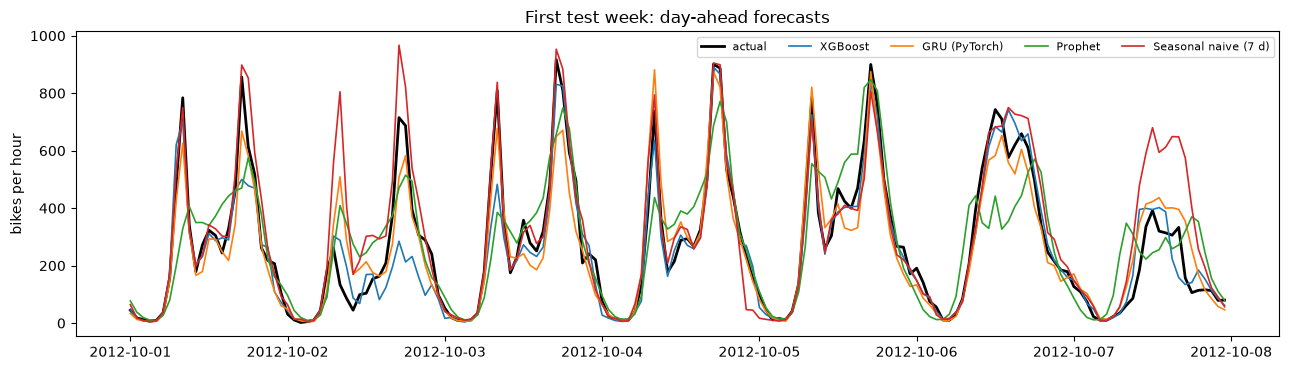

In [12]:
table_a = pd.DataFrame(results).T.sort_values("MAE (bikes/h)").round(1)
display(table_a)

week = slice(0, 24 * 7)
idx = bike.index[bike.index >= TEST_START][week]
plt.figure(figsize=(13, 3.8))
plt.plot(idx, y_true[week], color="black", lw=2, label="actual")
for name in ["XGBoost", "GRU (PyTorch)", "Prophet", "Seasonal naive (7 d)"]:
    plt.plot(idx, forecasts[name][week], lw=1.2, label=name)
plt.legend(ncol=5, fontsize=8); plt.title("First test week: day-ahead forecasts"); plt.ylabel("bikes per hour")
plt.tight_layout(); plt.show()

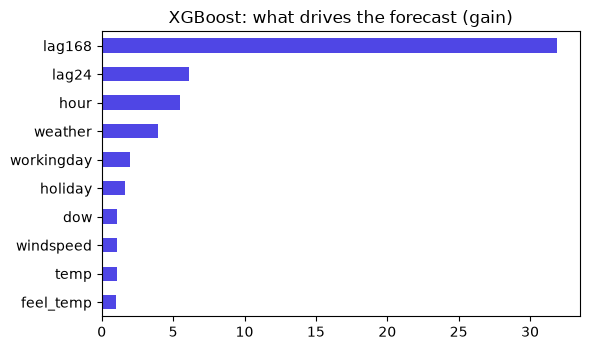

In [13]:
imp = pd.Series(xgb_model.get_booster().get_score(importance_type="gain")).sort_values()
imp.tail(10).plot.barh(figsize=(6, 3.6), color="#4f46e5", title="XGBoost: what drives the forecast (gain)")
plt.tight_layout(); plt.show()

### Why gradient boosting wins here
**XGBoost has the lowest error** (about 45 bikes per hour against 76 for seasonal naive) and trains in
seconds. The GRU comes close, within a few percent, after minutes of training; the LSTM and the
Transformer land a little further back. SARIMA and Prophet do worse than the one-line baseline: SARIMA's
linear structure, fitted on recent weeks, cannot represent the switch between working-day and weekend
patterns or the non-linear effect of weather, and Prophet never looks at the last few days, so it cannot
adjust to the current level of demand.

What makes this a gradient-boosting problem:
1. **The information is in a few strong, known features.** Hour of day, working day and weather decide
   most of the demand, and all of them are known when the forecast is made. A model that maps features to
   demand needs no memory of the past beyond a few lags.
2. **Sharp interactions.** "Rush hour, but only on working days" and "rain drops demand sharply" are
   exactly the if-then splits trees are made of; a neural network has to approximate them with smooth
   functions.
3. **Little data.** 21 months of one city is about 5,000 training windows: plenty for trees, modest for
   networks with tens of thousands of weights.
4. **Mixed inputs.** Categories, binary flags and continuous values of different scales need no scaling or
   embedding for trees.
5. **Cost and clarity.** Seconds instead of minutes, and a feature-importance chart that explains the model.

The networks were not useless: from the raw week of history they rediscovered most of the structure the
lag features gave XGBoost for free. With far more data (many cities, many years) that advantage grows.

## 3. Example 2: river flow driven by rain
Hydrologists forecast river flow to warn of floods. The flow at a river gauge depends on the rain that
fell on the catchment, but not in a simple way: rain first fills the soil, and only a wet soil produces
runoff; water then reaches the river over hours to days along slow and fast paths, with a delay and a shape
specific to each catchment. The soil moisture is a **hidden state** that is never measured directly.

We simulate **24 catchments** with a standard conceptual model (a soil store with a non-linear runoff
threshold, fast and slow reservoirs, and a catchment-specific routing delay), each with its own unknown
parameters, so the true behaviour is known and no licensing issue arises. On large real datasets of this
kind (for example CAMELS, 671 US catchments) LSTMs have outperformed both conceptual hydrology models and
tree ensembles, which is what this example reproduces in miniature.

**Task:** at each forecast origin, given the last 72 hours of rain and flow and the **rain forecast for the
next 48 hours**, predict the flow for those 48 hours. One model for all catchments, without telling it
which catchment it is looking at: it has to recognise the catchment's behaviour from the history.

### 3.1 Simulating the catchments

simulated 24 catchments x 17,520 hours in 2 s


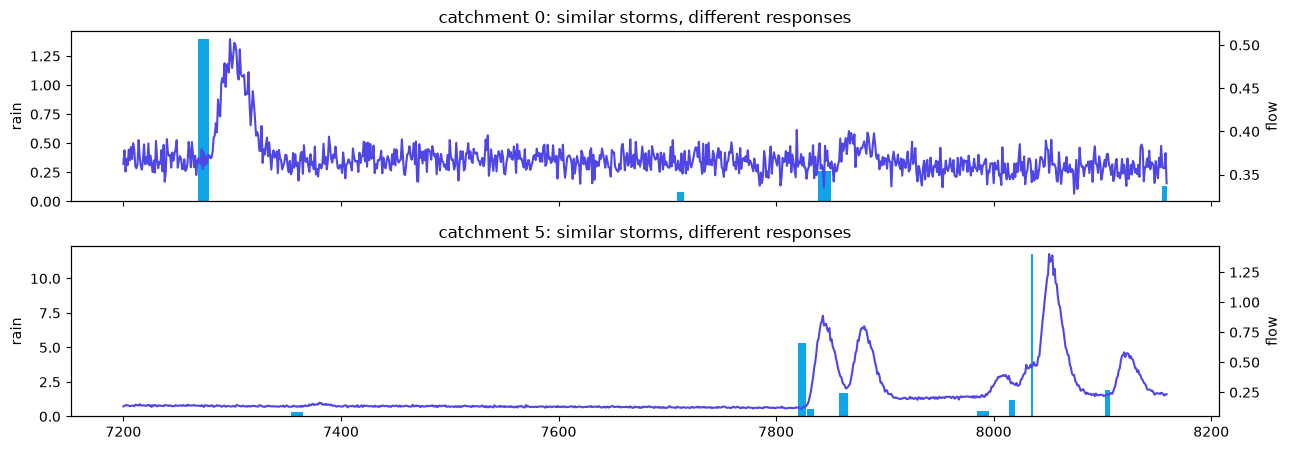

In [14]:
rng = np.random.default_rng(0)
HOURS = 24 * 365 * 2                                  # two years per catchment: year 1 to train, year 2 to test

def simulate_catchment(p, rng):
    t = np.arange(HOURS)
    season = 1 + 0.6 * np.sin(2 * np.pi * t / (24 * 365))
    rain = np.zeros(HOURS)
    for s in np.where(rng.random(HOURS) < 0.015 * season)[0]:          # storms: random starts, more in winter
        dur = rng.integers(2, 14)
        rain[s:s + dur] += rng.gamma(1.4, 7) / dur
    S, fast, slow, q = p["Smax"] * 0.4, 0.0, 0.0, np.zeros(HOURS)
    pet = 0.06 * (1 + 0.8 * np.sin(2 * np.pi * (t - 24 * 80) / (24 * 365)))   # evaporation, higher in summer
    for i in range(HOURS):
        runoff = rain[i] * (S / p["Smax"]) ** p["b"]                    # wet soil -> more of the rain runs off
        S = max(0.0, min(p["Smax"], S + rain[i] - runoff) - pet[i] * S / p["Smax"])
        fast += runoff; slow += 0.004 * S                               # fast surface path, slow groundwater path
        out = p["kf"] * fast + p["ks"] * slow
        fast -= p["kf"] * fast; slow -= p["ks"] * slow
        q[i] = out
    k = np.arange(48)
    uh = k ** (p["shape"] - 1) * np.exp(-k / p["scale"]); uh /= uh.sum()   # routing delay, unique per catchment
    flow = np.convolve(q, uh)[:HOURS]
    return rain, flow * (1 + 0.03 * rng.standard_normal(HOURS))       # 3% measurement noise

t0 = time.perf_counter()
catchments = []
for c in range(24):
    p = dict(Smax=rng.uniform(40, 220), b=rng.uniform(1.5, 4.5), kf=rng.uniform(0.1, 0.4),
             ks=rng.uniform(0.004, 0.02), shape=rng.uniform(1.5, 6), scale=rng.uniform(1.5, 5))
    catchments.append(simulate_catchment(p, rng))
print(f"simulated {len(catchments)} catchments x {HOURS:,} hours in {time.perf_counter() - t0:.0f} s")

fig, axes = plt.subplots(2, 1, figsize=(13, 4.6), sharex=True)
for ax, c in zip(axes, [0, 5]):
    rain, flow = catchments[c]
    sl = slice(24 * 300, 24 * 340)
    ax.bar(np.arange(sl.start, sl.stop), rain[sl], color="#0ea5e9", width=1, label="rain")
    ax2 = ax.twinx(); ax2.plot(np.arange(sl.start, sl.stop), flow[sl], color="#4f46e5", label="river flow")
    ax.set_ylabel("rain"); ax2.set_ylabel("flow"); ax.set_title(f"catchment {c}: similar storms, different responses")
plt.tight_layout(); plt.show()

Look at how differently the two catchments answer similar storms: the size of the response depends on how
wet the soil already was, and the delay and shape of the flood wave depend on the catchment.

In [15]:
L2, H2 = 72, 48
def windows(rain, flow, start, end, stride):
    X, R, Y = [], [], []
    for o in range(max(start, L2), end - H2, stride):
        X.append(np.stack([rain[o - L2:o], flow[o - L2:o]], 1)); R.append(rain[o:o + H2]); Y.append(flow[o:o + H2])
    return np.array(X, np.float32), np.array(R, np.float32), np.array(Y, np.float32)

YEAR = 24 * 365
tr = [windows(r, f, 0, YEAR - 24 * 30, 16) for r, f in catchments]             # training, last month held out
va = [windows(r, f, YEAR - 24 * 30, YEAR, 24) for r, f in catchments]          # validation for early stopping
te = [windows(r, f, YEAR, HOURS, 24) for r, f in catchments]                    # one forecast a day in year 2
stack = lambda parts, k: np.concatenate([p[k] for p in parts])
Xtr2, Rtr2, Ytr2 = (stack(tr, k) for k in range(3))
Xva2, Rva2, Yva2 = (stack(va, k) for k in range(3))
Xte2, Rte2, Yte2 = (stack(te, k) for k in range(3))
print("train", Xtr2.shape, "validation", Xva2.shape, "test", Xte2.shape)

results2, preds2 = {}, {}
def score2(name, pred, seconds):
    preds2[name] = pred
    results2[name] = {"MAE": float(np.mean(np.abs(pred - Yte2))), "RMSE": float(np.sqrt(np.mean((pred - Yte2) ** 2))),
                      "peak-hour MAE": float(np.mean(np.abs(pred - Yte2)[Yte2 > np.quantile(Yte2, 0.95)])), "seconds": seconds}
    r = results2[name]
    print(f"{name:<34} MAE {r['MAE']:.4f}  RMSE {r['RMSE']:.4f}  top-5% flows MAE {r['peak-hour MAE']:.4f}  ({seconds:.0f} s)")

score2("Persistence (last flow)", np.repeat(Xte2[:, -1:, 1], H2, 1), 0)

train (11880, 72, 2) validation (672, 72, 2) test (8712, 72, 2)
Persistence (last flow)            MAE 0.1186  RMSE 0.2649  top-5% flows MAE 0.6219  (0 s)


Seasonal naive, SARIMA and Prophet are left out here on purpose: river flow has no reliable daily or weekly
cycle, and its driver (rain) enters through a non-linear, state-dependent response that those models cannot
express. Persistence is the honest baseline.

### 3.2 Gradient boosting with the best features we can give it
The same recipe that won example 1: a table with the recent flow and rain, totals over the window, and the
forecast rain for each of the next 48 hours with its running total. One model for all lead times, with the
lead time as a feature.

In [16]:
def table(X, R):
    rain, flow = X[:, :, 0], X[:, :, 1]
    base = np.concatenate([flow[:, -24:], rain[:, -24:], rain.sum(1, keepdims=True), flow.mean(1, keepdims=True),
                           flow.max(1, keepdims=True), R, np.cumsum(R, 1)], 1)
    n = len(base)
    lead = np.tile(np.arange(H2), n)[:, None]
    return np.concatenate([np.repeat(base, H2, 0), lead], 1).astype(np.float32)

t0 = time.perf_counter()
gbm2 = xgb.XGBRegressor(n_estimators=500, max_depth=8, learning_rate=0.05, subsample=0.5, colsample_bytree=0.8,
                        tree_method="hist", n_jobs=4, random_state=0)
gbm2.fit(table(Xtr2, Rtr2), Ytr2.reshape(-1))
score2("XGBoost (engineered features)", gbm2.predict(table(Xte2, Rte2)).reshape(-1, H2), time.perf_counter() - t0)

XGBoost (engineered features)      MAE 0.0561  RMSE 0.1228  top-5% flows MAE 0.2991  (311 s)


### 3.3 Recurrent networks: encoder-decoder GRU (PyTorch) and LSTM (Keras)
An **encoder** reads the 72 past hours of rain and flow; its final hidden state is the network's own
estimate of the catchment's condition (how wet, how fast it responds). A **decoder** then walks through
the 48 forecast hours, reading the forecast rain one hour at a time and updating that state, exactly the way
the water moves through the catchment. No features are engineered.

In [17]:
r_sd, f_sd = Xtr2[:, :, 0].std(), Ytr2.std()
def norm(X, R):
    return np.concatenate([X[:, :, :1] / r_sd, X[:, :, 1:] / f_sd], 2).astype(np.float32), (R / r_sd)[..., None].astype(np.float32)
(Xtr_n, Rtr_n), (Xva_n, Rva_n), (Xte_n, Rte_n) = norm(Xtr2, Rtr2), norm(Xva2, Rva2), norm(Xte2, Rte2)

class Seq2SeqGRU(torch.nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.encoder = torch.nn.GRU(2, hidden, batch_first=True)
        self.decoder = torch.nn.GRU(1, hidden, batch_first=True)
        self.out = torch.nn.Linear(hidden, 1)
    def forward(self, x, r):
        _, state = self.encoder(x)                 # the learned "state of the catchment"
        y, _ = self.decoder(r, state)              # carried forward through the forecast rain
        return self.out(y).squeeze(-1)

torch.manual_seed(0)
net = Seq2SeqGRU(); opt = torch.optim.Adam(net.parameters(), lr=2e-3)
T = lambda a: torch.tensor(a)
xt, rt, yt = T(Xtr_n), T(Rtr_n), T(Ytr2 / f_sd)
xv, rv, yv = T(Xva_n), T(Rva_n), T(Yva2 / f_sd)
best, best_state, bad, t0 = np.inf, None, 0, time.perf_counter()
for ep in range(30):
    net.train()
    for i in torch.randperm(len(xt)).split(128):
        opt.zero_grad(); loss = torch.nn.functional.l1_loss(net(xt[i], rt[i]), yt[i]); loss.backward(); opt.step()
    net.eval()
    with torch.no_grad():
        v = torch.nn.functional.l1_loss(net(xv, rv), yv).item()
    if v < best:
        best, best_state, bad = v, {k: x.clone() for k, x in net.state_dict().items()}, 0
    else:
        bad += 1
        if bad >= 6:
            break
net.load_state_dict(best_state); net.eval()
with torch.no_grad():
    p = net(T(Xte_n), T(Rte_n)).numpy() * f_sd
score2("GRU encoder-decoder (PyTorch)", p, time.perf_counter() - t0); print(f"   {ep + 1} epochs")

GRU encoder-decoder (PyTorch)      MAE 0.0342  RMSE 0.0816  top-5% flows MAE 0.1799  (408 s)
   30 epochs


In [18]:
tf.keras.utils.set_random_seed(0)
enc_in = tf.keras.Input((L2, 2)); dec_in = tf.keras.Input((H2, 1))
_, h, c = tf.keras.layers.LSTM(64, return_state=True)(enc_in)
dec = tf.keras.layers.LSTM(64, return_sequences=True)(dec_in, initial_state=[h, c])
lstm2 = tf.keras.Model([enc_in, dec_in], tf.keras.layers.Dense(1)(dec))
lstm2.compile(optimizer=tf.keras.optimizers.Adam(2e-3), loss="mae")
t0 = time.perf_counter()
h2 = lstm2.fit([Xtr_n, Rtr_n], (Ytr2 / f_sd)[..., None], validation_data=([Xva_n, Rva_n], (Yva2 / f_sd)[..., None]),
               epochs=30, batch_size=128, verbose=0,
               callbacks=[tf.keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)])
score2("LSTM encoder-decoder (Keras)", lstm2.predict([Xte_n, Rte_n], verbose=0)[..., 0] * f_sd, time.perf_counter() - t0)
print(f"   {len(h2.history['loss'])} epochs")

LSTM encoder-decoder (Keras)       MAE 0.0379  RMSE 0.0915  top-5% flows MAE 0.2097  (280 s)
   23 epochs


### 3.4 Results

,MAE,RMSE,peak-hour MAE,seconds
GRU encoder-decoder (PyTorch),0.0342,0.0816,0.1799,407.6815
LSTM encoder-decoder (Keras),0.0379,0.0915,0.2097,280.1415
XGBoost (engineered features),0.0561,0.1228,0.2991,310.5952
Persistence (last flow),0.1186,0.2649,0.6219,0.0000


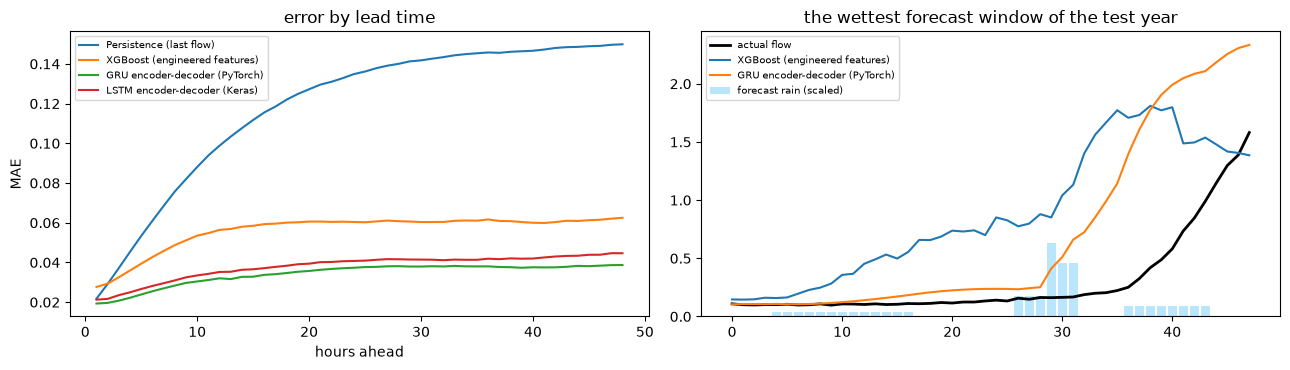

In [19]:
table_b = pd.DataFrame(results2).T.sort_values("MAE").round(4)
display(table_b)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for name in preds2:
    ax[0].plot(range(1, H2 + 1), np.mean(np.abs(preds2[name] - Yte2), 0), label=name)
ax[0].set_xlabel("hours ahead"); ax[0].set_ylabel("MAE"); ax[0].set_title("error by lead time"); ax[0].legend(fontsize=7)
i = int(np.argmax(Rte2.sum(1)))                                   # the forecast window with the most rain
ax[1].bar(range(H2), Rte2[i] / Rte2[i].max() * Yte2[i].max() * 0.4, color="#bae6fd", label="forecast rain (scaled)")
ax[1].plot(Yte2[i], color="black", lw=2, label="actual flow")
for name in ["XGBoost (engineered features)", "GRU encoder-decoder (PyTorch)"]:
    ax[1].plot(preds2[name][i], label=name)
ax[1].set_title("the wettest forecast window of the test year"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Why recurrent networks win here
The **GRU cuts the error by about 40% compared with XGBoost**, and by a similar margin on the top 5% of
flows, the floods a warning service exists for. The LSTM is close behind. The error-by-lead-time chart shows
where: the gap opens from the first hour and widens until about 12 hours ahead, as the forecast depends more
and more on how the catchment turns future rain into flow, then stays roughly constant.

Single storms vary, and the wettest window of the year (right-hand chart) is a hard case for both: XGBoost
raises the flow before any rain has fallen, while the GRU gets the timing of the rise roughly right but
overestimates the peak. The averages over 8,700 forecasts above are what decide between models; individual
storms are where you look for what to improve next.

What makes this a neural-network problem:
1. **A hidden state.** Flow depends on how wet the soil is, which is never measured and summarises weeks
   of history. The encoder's final hidden state is a learned estimate of that condition; a tree sees only the
   fixed columns it is given.
2. **A smooth, repeated response.** Each hour of forecast rain adds a delayed, catchment-specific pulse of
   flow. The decoder applies the same update rule hour by hour (the same weights at every step), so it learns
   the response once; a tree must learn separate splits for every combination of rain hour and lead time.
3. **Behaviour to infer.** The model is not told which catchment it sees. The recurrent state carries what
   it inferred from the history (fast or slow, delayed or immediate) into the forecast.
4. **Enough shared data.** 24 catchments train one model, so patterns learned on one help the others.

The comparison is fair to XGBoost but not exhaustive: a hydrologist would engineer a soil-moisture feature
(an antecedent precipitation index) and narrow the gap; exercise 2 measures how much. The network learns that
feature by itself, which is the real advantage when the right features are not known in advance.

## 4. A decision guide

| Your problem looks like... | Start with | Then try |
|---|---|---|
| one or a few series, stable seasonality, few years of data | seasonal naive, ETS/SARIMA | Prophet if you need explainable components and holidays |
| a table of strong drivers known at forecast time (calendar, weather, prices, promotions) | **gradient boosting** (XGBoost, LightGBM) with lag features | a blend of boosting and a linear model |
| many related series (thousands of products, sensors, catchments) | a global gradient boosting model | a global RNN or Transformer |
| hidden state, long memory, smooth responses to inputs spread over time (hydrology, physiology, energy storage) | **recurrent networks** (GRU/LSTM encoder-decoder) | Transformers, or physics-based features for boosting |
| very long histories, lots of data, high frequency | Transformers (PatchTST, TFT) | foundation models (Chronos, TimesFM) as zero-shot baselines |
| little data and no time | seasonal naive, then a foundation model zero-shot | |

Whatever you choose: split by time, compare against a naive baseline, look at errors by lead time and on
the events that matter (peaks, rush hours), and prefer the simplest model that is clearly better.

## Exercises
1. In example 1, drop the weather columns from XGBoost. How much worse does it get, and does a neural network close the gap?
2. In example 2, add an *antecedent precipitation index* (an exponentially weighted sum of past rain, the hydrologist's proxy for soil moisture) to the XGBoost table. How much of the gap to the GRU does one well-chosen feature close?
3. Train the example 2 GRU on only 6 catchments and test on the other 18. Does it still beat XGBoost on catchments it has never seen?
4. Use `pip install chronos-forecasting` to add a zero-shot foundation model to example 1.